# Train on the full experimental set, test on the Anthropic set

Compare three score sets on the Anthropic
[claude-protein-binder-design](https://huggingface.co/datasets/Anthropic/claude-protein-binder-design)
designs. Select the **PPI** kernel, then choose **Run All**. This notebook reads
completed run exports; it does not train models or modify results.

| Method | Encoder | Head | Trained on the 3,669 experimental designs? |
|---|---|---|---|
| **GraPPI** | frozen `2layers_10hdim_esm` | cross-attn pooling + 2-layer MLP | yes |
| **ESM** | none (raw 1,280-dim ESM-2 features) | same head config | yes |
| **Original head** | frozen `2layers_10hdim_esm` | published `..._jkmean` classifier | no — inference only |

**Read this before quoting any number.** The GraPPI and ESM runs use the
Anthropic labels for early stopping (`select_on: test`), so their Anthropic
metrics are **optimistic and not blind-test estimates** — the same limitation
the leave-one-target-out study carries. The **Original head** row involves no
training and its fold was chosen by the head's original training
`fold_val_score`, so that row *is* a genuine held-out evaluation. The three rows
are therefore not interchangeable as evidence, even though they share a cohort.

Of 1,320 labeled Anthropic designs, only those with a released `designed.cif`
(about 1,189) are scored. The rest are reported as coverage and are never
treated as negatives. Groups with a single class — the `MBP` target has zero
positives — report NaN rather than a substituted 0.5, and are left out of the
medians.

In [1]:
from pathlib import Path
import importlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_curve, roc_curve

# Works whether the notebook starts in the repository root or in this folder.
cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents)
                  if (p / 'exp_train_anthr_test' / 'config_exp_train_anthr_test.yaml').is_file()),
                 None)
if REPO_ROOT is None:
    raise RuntimeError('Start the notebook from GraPPI or set REPO_ROOT to the repository path.')
PKG_DIR = REPO_ROOT / 'exp_train_anthr_test'
for _p in (str(REPO_ROOT), str(PKG_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import anthr_eval
import compare_results
importlib.reload(anthr_eval)
importlib.reload(compare_results)

# ---- paths (edit if a run was written elsewhere) ----
RESULTS_ROOT = REPO_ROOT.parent / 'GraPPI_data' / 'trained_data_ssl_finetune'
SOURCES = compare_results.resolve_sources(RESULTS_ROOT)
LABELS_FILE = REPO_ROOT.parent / 'GraPPI_data' / 'anthr_binder_data' / 'labels.csv'
STRATA = ['target', 'design_model', 'campaign']
TARGET_TO_PLOT = 'TREM2'   # per-target PR curve; change to any target name

# ---- chart style: validated categorical slots 1-3, assigned in fixed order ----
PALETTE = {'GraPPI': '#2a78d6', 'ESM': '#eb6834', 'Original head': '#1baf7a'}
MARKERS = {'GraPPI': 'o', 'ESM': 's', 'Original head': '^'}
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3e0'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'grid.color': GRID,
    'axes.grid': True, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
})

print(f'Repository: {REPO_ROOT}')
print(f'Results root: {RESULTS_ROOT}')

Repository: /mnt/poisson/data/zhisong/GraPPI
Results root: /mnt/poisson/data/zhisong/GraPPI_data/trained_data_ssl_finetune


## Run availability

Each run writes its exports after training finishes. A `*_best.pt` checkpoint can
exist while the run is still going, so its presence is not a completion signal —
check the summary timestamp. Missing runs are skipped here rather than raising,
so this notebook stays usable while one is still training.

In [2]:
frames, missing = compare_results.load_available(SOURCES, verbose=False)

status_rows = []
summaries = {}
for method, path in SOURCES.items():
    summary_path = compare_results.summary_path_for(path)
    summary = json.loads(summary_path.read_text()) if summary_path.is_file() else None
    summaries[method] = summary
    status_rows.append({
        'method': method,
        'status': 'scores present' if method in frames else 'waiting for exports',
        'n_scored': len(frames[method]) if method in frames else 0,
        'summary': 'present' if summary else 'missing',
        'modified': (pd.Timestamp.fromtimestamp(summary_path.stat().st_mtime)
                     if summary_path.is_file() else pd.NaT),
        'path': str(path.parent),
    })
display(pd.DataFrame(status_rows).set_index('method'))

if not frames:
    print('No score CSVs found yet. Run train_exp_anthr.py and score_original_head.py first.')
else:
    try:
        compare_results.align(frames)
        print(f'Cohort check passed: {len(frames)} method(s) over the same '
              f'{len(next(iter(frames.values())))} designs with identical labels.')
    except ValueError as exc:
        print(f'COHORT MISMATCH — metrics below are not directly comparable:\n  {exc}')

,status,n_scored,summary,modified,path
method,,,,,
GraPPI,scores present,1186,present,2026-11-04 15:16:30.141015,/mnt/poisson/data/zhisong/GraPPI_data/trained_...
ESM,scores present,1186,present,2026-11-04 15:16:58.528758,/mnt/poisson/data/zhisong/GraPPI_data/trained_...
Original head,waiting for exports,0,missing,NaT,/mnt/poisson/data/zhisong/GraPPI_data/trained_...


Cohort check passed: 2 method(s) over the same 1186 designs with identical labels.


## Provenance and the selection caveat, per run

`best_epoch` and `select_on` show how each trained run was stopped. Where
`select_on` is `test`, that run read the Anthropic labels to choose its epoch.
`train_fit` is the model's fit on its own training data at that epoch — useful
for spotting overfitting, not a performance claim.

In [3]:
prov_rows = []
for method, summary in summaries.items():
    if not summary:
        continue
    fit = summary.get('train_fit_at_best_epoch') or {}
    prov_rows.append({
        'method': method,
        'protocol': summary.get('protocol', ''),
        'select_on': summary.get('select_on', 'n/a (no training)'),
        'best_epoch': summary.get('best_epoch', np.nan),
        'epochs_run': summary.get('n_epochs_run', np.nan),
        'pos_weight': summary.get('pos_weight', np.nan),
        'n_train': summary.get('n_train', np.nan),
        'train_fit_AP': fit.get('ap', np.nan),
        'train_fit_AUROC': fit.get('auroc', np.nan),
        'coverage': summary.get('coverage', ''),
    })
if prov_rows:
    display(pd.DataFrame(prov_rows).set_index('method').T)
    blind = [m for m, s in summaries.items()
             if s and s.get('select_on') == 'test']
    if blind:
        display(Markdown(
            f"**Not blind:** {', '.join(blind)} selected the stopping epoch on the "
            'Anthropic labels. Treat those metrics as optimistic.'))
else:
    print('Run summaries will appear once the runs finish.')

method,GraPPI,ESM
protocol,train_on_full_exp__test_on_anthropic,train_on_full_exp__test_on_anthropic
select_on,test,test
best_epoch,6,10
epochs_run,26,30
pos_weight,8.312183,8.312183
n_train,3669,3669
train_fit_AP,0.590333,0.759576
train_fit_AUROC,0.924255,0.961032
coverage,1186/1320 labeled Anthropic designs scored (13...,1186/1320 labeled Anthropic designs scored (13...


**Not blind:** GraPPI, ESM selected the stopping epoch on the Anthropic labels. Treat those metrics as optimistic.

## Headline comparison

Pooled metrics treat all scored designs as one cohort. The across-target median
gives each target equal weight instead, which is the fairer read when target
sizes and prevalences differ as much as they do here. `pooled_ap_lift` is pooled
AP divided by prevalence: 1.0 means no better than random ranking.

In [4]:
if frames:
    pooled = compare_results.pooled_table(frames, STRATA)
    keep = [c for c in pooled.columns
            if c.startswith('pooled_') or c.startswith('target_')]
    display(pooled[keep].T.round(4))
else:
    print('The summary table will appear when at least one run is available.')

method,GraPPI,ESM
pooled_n,1186.0000,1186.0000
pooled_n_pos,322.0000,322.0000
pooled_n_neg,864.0000,864.0000
pooled_prevalence,0.2715,0.2715
pooled_auroc,0.6196,0.5792
pooled_ap,0.3608,0.3589
pooled_ap_lift,1.3289,1.3219
target_ap_median,0.3002,0.2731
target_ap_q25,0.1566,0.1588
target_ap_q75,0.5257,0.5319


## Per-target results

`dataset_n` is the labeled design count for that target; `n` is how many were
actually scored, and `n_excluded` is the difference (designs with no released
structure). AP is scikit-learn's `average_precision_score`; `lift` divides it by
that target's prevalence among the scored designs. Targets with very few
positives give unstable AP estimates — read them alongside `n_pos`.

In [5]:
def per_stratum_frame(frames, key, dataset_counts=None):
    # One row per group, with each method's AP / AUROC / lift side by side.
    merged = None
    for method, frame in frames.items():
        table = pd.DataFrame(anthr_eval.stratified_metrics(frame.to_dict('records'), key))
        counts = table[[key, 'n', 'n_pos', 'n_neg', 'prevalence']]
        scores = table[[key, 'ap', 'auroc', 'ap_lift']].rename(columns={
            'ap': f'{method} AP', 'auroc': f'{method} AUROC', 'ap_lift': f'{method} lift'})
        merged = counts.merge(scores, on=key) if merged is None else merged.merge(scores, on=key)
    if merged is None:
        return pd.DataFrame()
    if dataset_counts is not None:
        merged = dataset_counts.merge(merged, on=key, how='right')
        merged['n_excluded'] = merged['dataset_n'] - merged['n']
        front = [key, 'dataset_n', 'n', 'n_excluded', 'n_pos', 'n_neg', 'prevalence']
        merged = merged[front + [c for c in merged.columns if c not in front]]
    return merged.sort_values('n', ascending=False).reset_index(drop=True)


dataset_counts = None
if LABELS_FILE.is_file():
    labels_all = pd.read_csv(LABELS_FILE)
    dataset_counts = (labels_all.groupby('target').size()
                      .rename('dataset_n').reset_index())

if frames:
    per_target = per_stratum_frame(frames, 'target', dataset_counts)
    display(per_target.round(4))
    scored = per_target['n'].sum()
    total = per_target['dataset_n'].sum() if 'dataset_n' in per_target else np.nan
    print(f'Scored {scored} of {total} labeled designs '
          f'({total - scored if total == total else "?"} without a prepared structure).')
else:
    print('The per-target table will appear when at least one run is available.')

,target,dataset_n,n,n_excluded,n_pos,n_neg,prevalence,GraPPI AP,GraPPI AUROC,GraPPI lift,ESM AP,ESM AUROC,ESM lift
0,TNFa,150,132,18,4,128,0.0303,0.0576,0.6895,1.9006,0.1354,0.8496,4.4694
1,EGFR,90,90,0,10,80,0.1111,0.1341,0.5337,1.2065,0.1201,0.4925,1.0808
2,BBF-14,90,90,0,3,87,0.0333,0.1184,0.6475,3.5531,0.0921,0.6820,2.7638
3,TREM2,90,90,0,72,18,0.8000,0.8068,0.6173,1.0084,0.8348,0.5941,1.0435
4,TrkA,90,90,0,20,70,0.2222,0.2512,0.5193,1.1306,0.2318,0.3436,1.0432
5,MBP,90,88,2,0,88,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
6,RBX1,90,82,8,28,54,0.3415,0.3491,0.4782,1.0222,0.4130,0.5734,1.2095
7,IL-7Ra,90,80,10,47,33,0.5875,0.7054,0.5654,1.2008,0.6068,0.5119,1.0328
8,PD-L1,90,78,12,39,39,0.5000,0.4764,0.5201,0.9528,0.5426,0.5325,1.0851
9,VEGF-A,90,78,12,46,32,0.5897,0.6212,0.5258,1.0533,0.6192,0.5530,1.0499


Scored 1186 of 1320 labeled designs (134 without a prepared structure).


## By design model and campaign

The Anthropic designs come from two models (Mythos Preview, Opus 4.8) across
several campaigns. These splits show whether a score set behaves differently by
design provenance rather than by target.

In [6]:
if frames:
    for key in ('design_model', 'campaign'):
        if key not in next(iter(frames.values())).columns:
            print(f'[skip] {key}: not present in the score CSVs')
            continue
        display(Markdown(f'#### By {key}'))
        display(per_stratum_frame(frames, key).round(4))
else:
    print('These tables will appear when at least one run is available.')

#### By design_model

,design_model,n,n_pos,n_neg,prevalence,GraPPI AP,GraPPI AUROC,GraPPI lift,ESM AP,ESM AUROC,ESM lift
0,Mythos Preview,837,261,576,0.3118,0.4159,0.6238,1.3337,0.4021,0.567,1.2894
1,Opus 4.8,349,61,288,0.1748,0.2236,0.5959,1.2792,0.2479,0.603,1.4183


#### By campaign

,campaign,n,n_pos,n_neg,prevalence,GraPPI AP,GraPPI AUROC,GraPPI lift,ESM AP,ESM AUROC,ESM lift
0,multi_target,648,161,487,0.2485,0.3481,0.6043,1.4010,0.3539,0.5909,1.4246
1,single_target,508,159,349,0.3130,0.4170,0.6487,1.3324,0.3815,0.5605,1.2190
2,single_target_supplementary,30,2,28,0.0667,0.1769,0.7321,2.6538,0.2917,0.8571,4.3750


## Per-target AP and AUROC

Targets are ordered by scored sample count. The black tick is that target's
prevalence — the reference an AP should beat. The dashed line on the right panel
is AUROC 0.5. Points are omitted where a target has only one class.

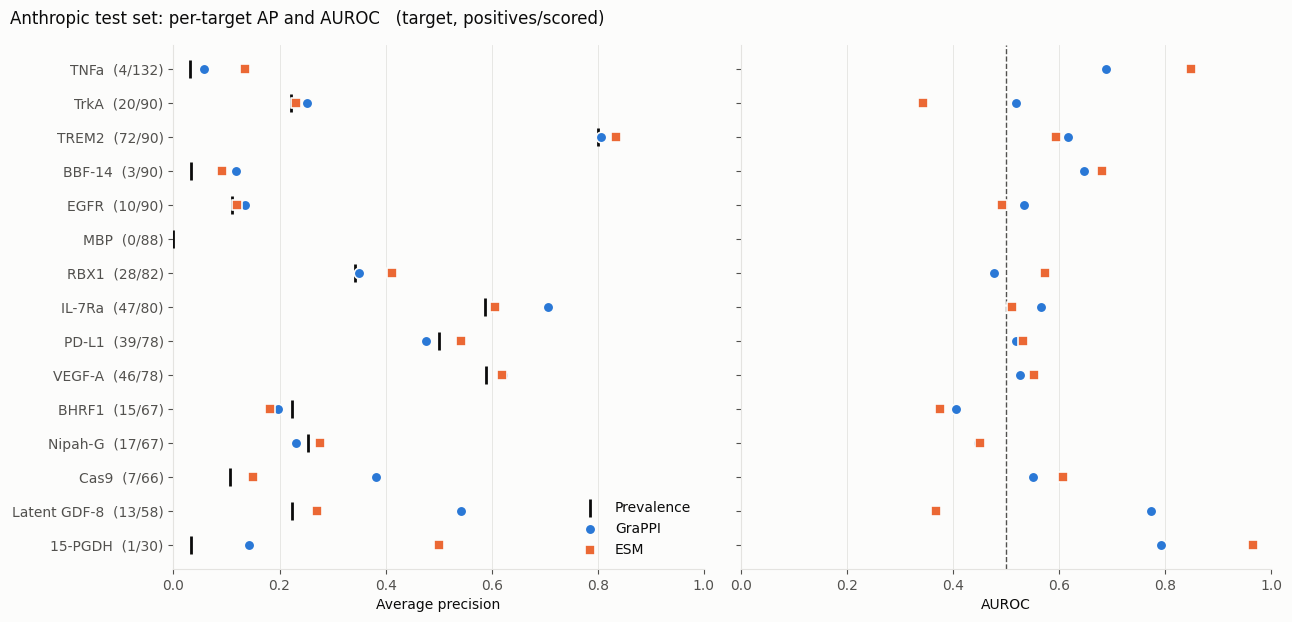

In [7]:
if frames:
    chart = per_target.loc[per_target['n'] > 0].sort_values('n').reset_index(drop=True)
    y = np.arange(len(chart))
    fig, axes = plt.subplots(1, 2, figsize=(13, max(4.5, len(chart) * 0.42)), sharey=True)

    axes[0].scatter(chart['prevalence'], y, marker='|', s=160, color=INK,
                    label='Prevalence', zorder=3)
    for method in frames:
        axes[0].scatter(chart[f'{method} AP'], y, marker=MARKERS.get(method, 'o'),
                        s=58, color=PALETTE.get(method), label=method,
                        edgecolors=SURFACE, linewidths=1.2, zorder=4)
        axes[1].scatter(chart[f'{method} AUROC'], y, marker=MARKERS.get(method, 'o'),
                        s=58, color=PALETTE.get(method), label=method,
                        edgecolors=SURFACE, linewidths=1.2, zorder=4)
    axes[1].axvline(0.5, color=MUTED, linestyle='--', linewidth=1, zorder=2)

    axes[0].set_xlabel('Average precision')
    axes[1].set_xlabel('AUROC')
    axes[0].set_yticks(y)
    axes[0].set_yticklabels([f'{r.target}  ({int(r.n_pos)}/{int(r.n)})'
                             for r in chart.itertuples()])
    axes[0].set_xlim(0, 1)
    axes[1].set_xlim(0, 1)
    for ax in axes:
        ax.grid(axis='y', visible=False)
    axes[0].legend(loc='lower right')
    fig.suptitle('Anthropic test set: per-target AP and AUROC   '
                 '(target, positives/scored)', x=0.01, ha='left', fontsize=12)
    fig.tight_layout()
    plt.show()
else:
    print('Plots will appear when at least one run is available.')

## Precision–recall curves

The left panel pools all scored designs; the right panel shows one target, set
by `TARGET_TO_PLOT` in the setup cell. The dashed horizontal line is prevalence,
the no-skill reference. Pooled curves mix targets with very different
prevalences, so the pooled shape is not a per-target performance claim.

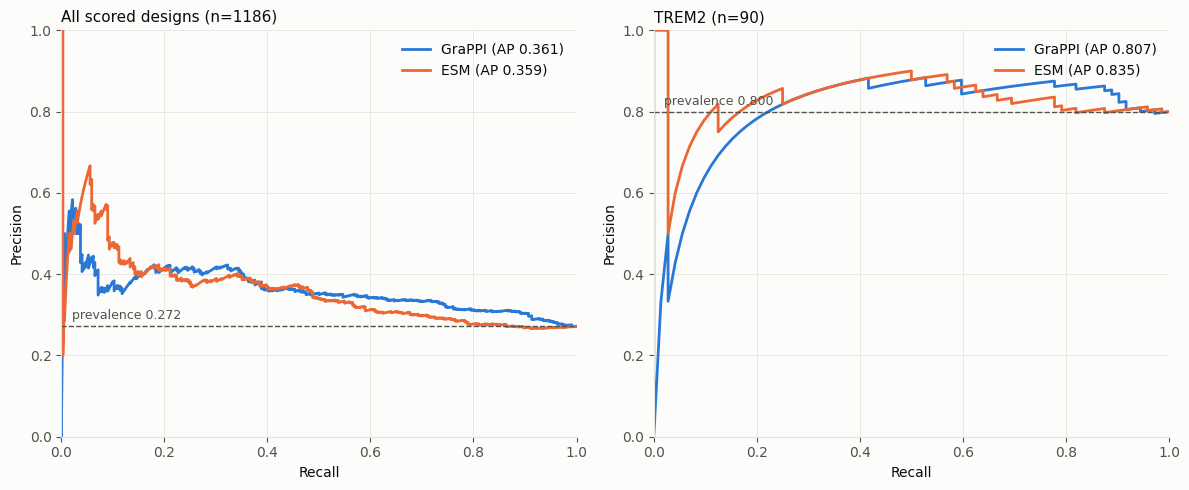

In [8]:
def pr_panel(ax, data, title):
    for method, frame in data.items():
        if frame['label'].nunique() < 2:
            continue
        precision, recall, _ = precision_recall_curve(frame['label'], frame['prob'])
        ap = anthr_eval.binary_metrics(frame['label'], frame['prob'])['ap']
        ax.plot(recall, precision, color=PALETTE.get(method),
                label=f'{method} (AP {ap:.3f})')
    any_frame = next(iter(data.values()))
    prevalence = float((any_frame['label'] == 1).mean())
    ax.axhline(prevalence, color=MUTED, linestyle='--', linewidth=1)
    ax.annotate(f'prevalence {prevalence:.3f}', (0.02, prevalence),
                textcoords='offset points', xytext=(0, 5), color=MUTED, fontsize=9)
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(title, loc='left', fontsize=11)
    ax.legend(loc='upper right')


if frames:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    pr_panel(axes[0], frames, f'All scored designs (n={len(next(iter(frames.values())))})')

    target_frames = {m: f.loc[f['target'] == TARGET_TO_PLOT] for m, f in frames.items()}
    if any(f.empty for f in target_frames.values()):
        axes[1].set_axis_off()
        axes[1].text(0.5, 0.5, f'{TARGET_TO_PLOT!r} not found in the score sets',
                     ha='center', va='center', color=MUTED)
    elif next(iter(target_frames.values()))['label'].nunique() < 2:
        axes[1].set_axis_off()
        axes[1].text(0.5, 0.5, f'{TARGET_TO_PLOT} has a single class;\nno PR curve',
                     ha='center', va='center', color=MUTED)
    else:
        n_t = len(next(iter(target_frames.values())))
        pr_panel(axes[1], target_frames, f'{TARGET_TO_PLOT} (n={n_t})')
    fig.tight_layout()
    plt.show()
else:
    print('Curves will appear when at least one run is available.')

## Training curves

Training loss and held-out AP are plotted as separate panels on their own scales
— never as two y-axes on one chart. The marked point is the selected epoch.
Where `select_on` is `test`, the right panel *is* the selection signal, which is
exactly why those metrics are optimistic.

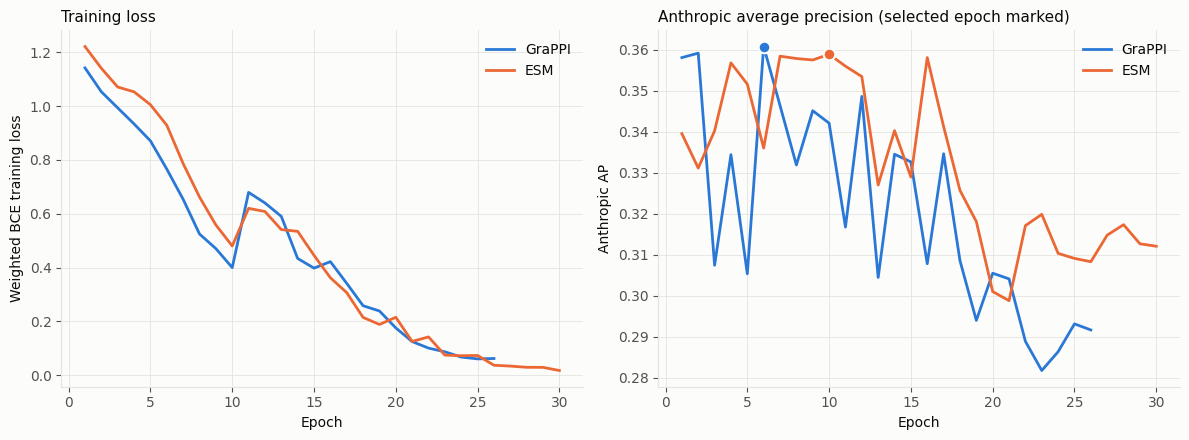

In [9]:
logs = {}
for method, path in SOURCES.items():
    log_path = Path(str(path).replace('_raw_scores.csv', '_epoch_log.csv'))
    if log_path.is_file():
        logs[method] = pd.read_csv(log_path)

if logs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for method, log in logs.items():
        color = PALETTE.get(method)
        axes[0].plot(log['epoch'], log['train_loss'], color=color, label=method)
        axes[1].plot(log['epoch'], log['test_ap'], color=color, label=method)
        summary = summaries.get(method) or {}
        best = summary.get('best_epoch')
        if best and best <= len(log):
            row = log.loc[log['epoch'] == best]
            if not row.empty:
                axes[1].scatter(row['epoch'], row['test_ap'], color=color,
                                s=70, zorder=5, edgecolors=SURFACE, linewidths=1.5)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Weighted BCE training loss')
    axes[0].set_title('Training loss', loc='left', fontsize=11)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Anthropic AP')
    axes[1].set_title('Anthropic average precision (selected epoch marked)',
                      loc='left', fontsize=11)
    for ax in axes:
        ax.legend(loc='best')
    fig.tight_layout()
    plt.show()
else:
    print('Epoch logs appear for the trained runs only (the published head is inference only).')

## Score distributions

One panel per method, binder vs non-binder. A classifier that separates the two
classes shows two displaced distributions; heavily overlapping distributions
piled against one edge indicate scores that are nearly uninformative on this
dataset, regardless of what the ranking metrics say.

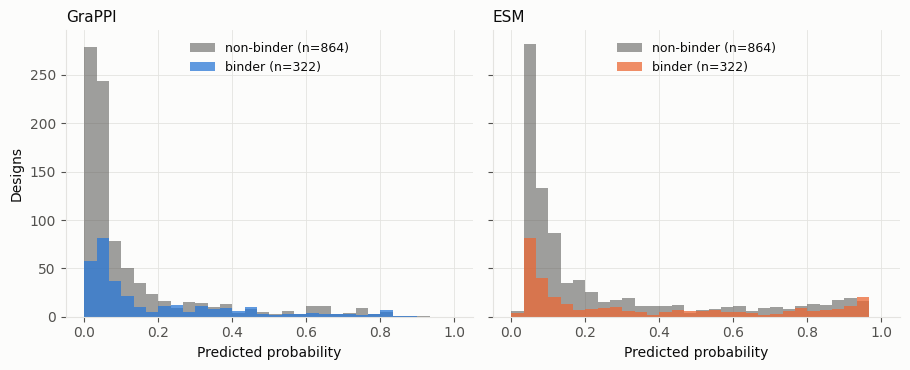

In [10]:
if frames:
    fig, axes = plt.subplots(1, len(frames), figsize=(4.6 * len(frames), 3.8),
                             sharey=True, squeeze=False)
    bins = np.linspace(0, 1, 31)
    for ax, (method, frame) in zip(axes[0], frames.items()):
        for label, style in ((0, dict(color=MUTED, alpha=0.55)),
                             (1, dict(color=PALETTE.get(method), alpha=0.75))):
            subset = frame.loc[frame['label'] == label, 'prob']
            ax.hist(subset, bins=bins, label=f'{"binder" if label else "non-binder"}'
                    f' (n={len(subset)})', **style)
        ax.set_title(method, loc='left', fontsize=11)
        ax.set_xlabel('Predicted probability')
        ax.legend(loc='upper center', fontsize=9)
    axes[0][0].set_ylabel('Designs')
    fig.tight_layout()
    plt.show()
else:
    print('Distributions will appear when at least one run is available.')

## Export

Writes the same tables `compare_results.py` produces, so results can be shared
without rerunning the notebook.

In [11]:
if frames:
    out_dir = RESULTS_ROOT / 'anthr_comparison'
    out_dir.mkdir(parents=True, exist_ok=True)
    compare_results.pooled_table(frames, STRATA).T.to_csv(
        out_dir / 'anthr_comparison_summary.csv')
    per_target.to_csv(out_dir / 'anthr_comparison_per_target.csv', index=False)
    for key in ('design_model', 'campaign'):
        if key in next(iter(frames.values())).columns:
            per_stratum_frame(frames, key).to_csv(
                out_dir / f'anthr_comparison_per_{key}.csv', index=False)
    print(f'Wrote comparison tables -> {out_dir}')
else:
    print('Nothing to export yet.')

Wrote comparison tables -> /mnt/poisson/data/zhisong/GraPPI_data/trained_data_ssl_finetune/anthr_comparison
